In [3]:
# importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              roc_curve, auc, roc_auc_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
pd.set_option("display.max_columns", None)

In [4]:
# load dataset
df = pd.read_csv("//content/mushroom_dataset.csv", sep=";")
print(f"Shape of the dataset is {df.shape}. This dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Shape of the dataset is (61069, 21). This dataset contains 61069 rows and 21 columns.


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,17.09,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,18.19,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,17.74,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,15.98,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,17.20,s,y,w,u,w,t,p,NaN,d,w


In [5]:
# selecting numerical features
numerical_data = df.select_dtypes(include="number")
numerical_features = numerical_data.columns.tolist()
print(f"There are {len(numerical_features)} numerical features:\n{numerical_features}")
print()
# selecting categorical features
categorical_features = [c for c in df.columns if c not in numerical_features and c != "class"]
print(f"There are {len(categorical_features)} categorical features:\n{categorical_features}")

There are 3 numerical features:
['cap-diameter', 'stem-height', 'stem-width']

There are 17 categorical features:
['cap-shape', 'cap-surface', 'cap-color', 'does-bruise-or-bleed', 'gill-attachment', 'gill-spacing', 'gill-color', 'stem-root', 'stem-surface', 'stem-color', 'veil-type', 'veil-color', 'has-ring', 'ring-type', 'spore-print-color', 'habitat', 'season']


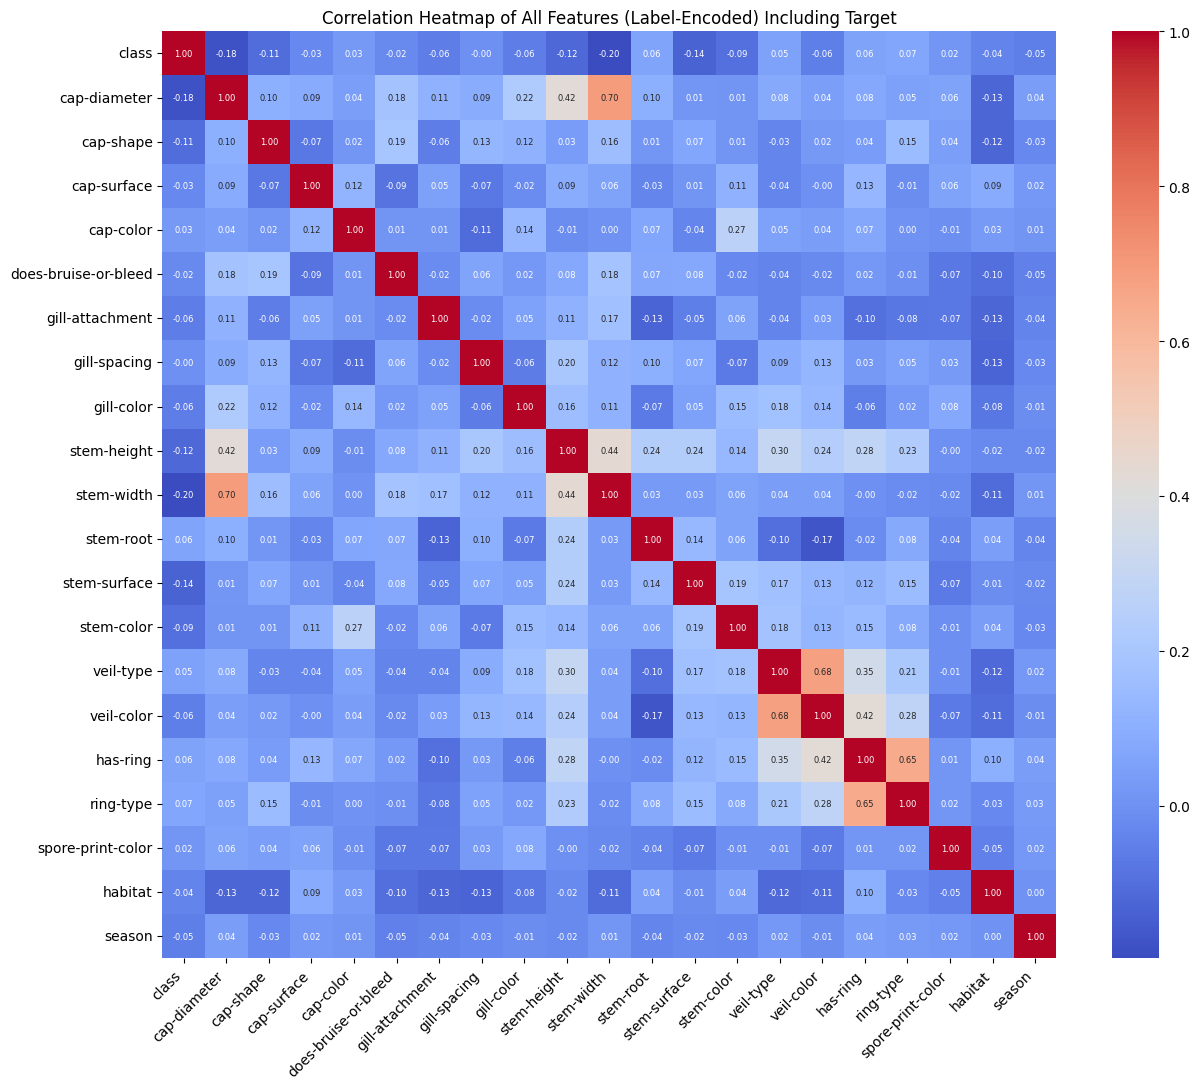

In [6]:
# full correlation heatmap
df_le = df.copy()
for c in df_le.columns:
    if df_le[c].dtype == object or pd.api.types.is_string_dtype(df_le[c]):
        df_le[c] = LabelEncoder().fit_transform(df_le[c].fillna("missing").astype(str))

plt.figure(figsize=(13, 11))
sns.heatmap(df_le.corr(), annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size": 6})
plt.title("Correlation Heatmap of All Features (Label-Encoded) Including Target")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

class
p    33888
e    27181
Name: count, dtype: int64
class
p    55.5
e    44.5
Name: count, dtype: float64


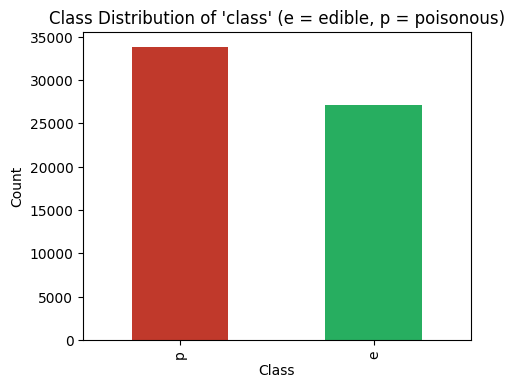

In [7]:
# imbalanced dataset check
clas = df["class"].value_counts()
print(clas)
print((clas / len(df) * 100).round(1))
clas.plot(kind="bar", figsize=(5, 4), color=["#c0392b", "#27ae60"])
plt.title("Class Distribution of 'class' (e = edible, p = poisonous)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

veil-type            94.797688
spore-print-color    89.595376
veil-color           87.861272
stem-root            84.393064
stem-surface         62.427746
gill-spacing         41.040462
cap-surface          23.121387
gill-attachment      16.184971
ring-type             4.046243
dtype: float64


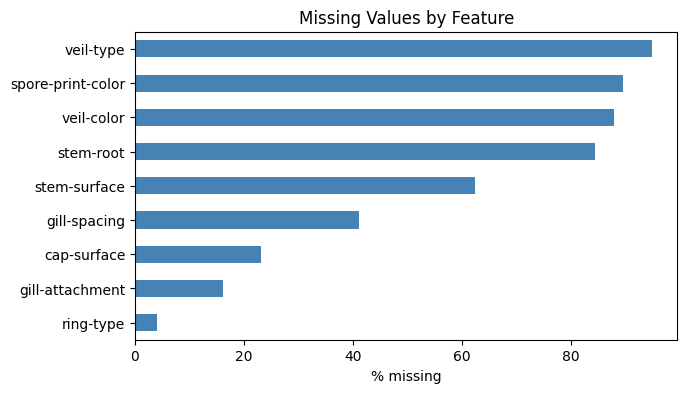

In [8]:
# missing values per column
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing_pct[missing_pct > 0])
missing_pct[missing_pct > 0].plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.xlabel("% missing")
plt.title("Missing Values by Feature")
plt.gca().invert_yaxis()
plt.show()

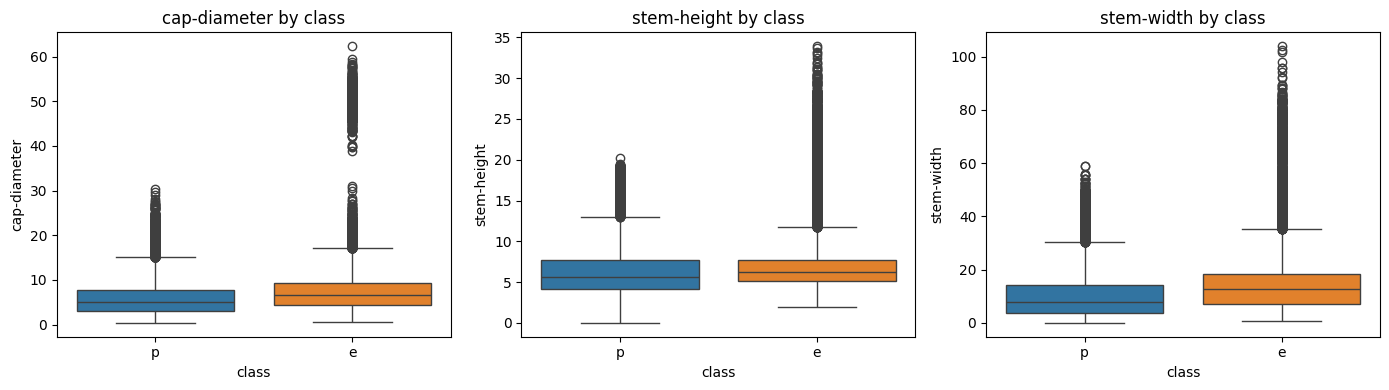

In [9]:
#EDA- numeric feature distributions by class
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, numerical_features):
    sns.boxplot(data=df, x="class", y=col, hue="class", legend=False, ax=ax)
    ax.set_title(f"{col} by class")
plt.tight_layout()
plt.show()

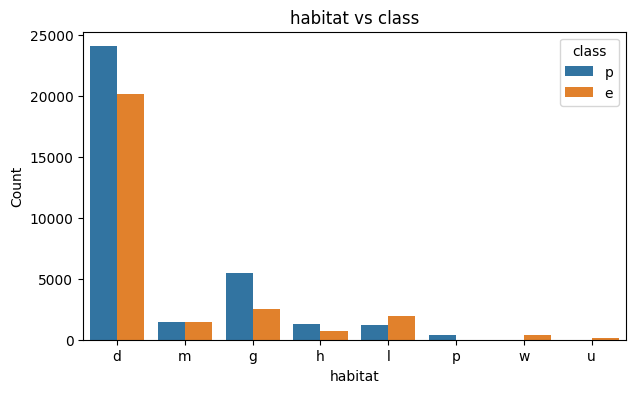

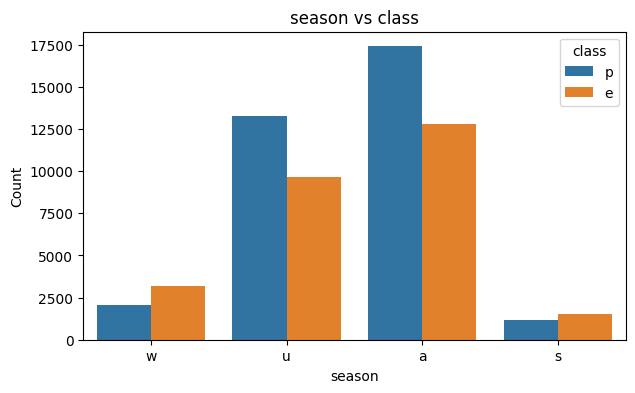

In [10]:
#EDA- categorical features vs class
category = ["habitat", "season"]
for col in category:
    plt.figure(figsize=(7, 4))
    plt.title(f"{col} vs class")
    sns.countplot(x=col, hue="class", data=df)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()
    print()

In [11]:
# 1. handling missing values
drop_cols = ["veil-type", "veil-color", "spore-print-color", "stem-root", "stem-surface"]
df = df.drop(columns=drop_cols)
impute_cols = ["cap-surface", "gill-attachment", "gill-spacing", "ring-type"]
for c in impute_cols:
    df[c] = df[c].fillna("missing")

print("Missing values after cleanup:\n", df.isnull().sum().sum())

Missing values after cleanup:
 0


In [12]:
# 2.categorical encoding
df["class"] = df["class"].map({"e": 0, "p": 1})  # target: 0 = edible, 1 = poisonous
numerical_features = ["cap-diameter", "stem-height", "stem-width"]
categorical_features = [c for c in df.columns if c not in numerical_features + ["class"]]

X = pd.get_dummies(df[categorical_features], drop_first=True)
X[numerical_features] = df[numerical_features]
y = df["class"]

print("Feature matrix shape after one-hot encoding:", X.shape)
X.head()

Feature matrix shape after one-hot encoding: (61069, 84)


,cap-shape_c,cap-shape_f,cap-shape_o,cap-shape_p,cap-shape_s,cap-shape_x,cap-surface_e,cap-surface_g,cap-surface_h,cap-surface_i,cap-surface_k,cap-surface_l,cap-surface_missing,cap-surface_s,cap-surface_t,cap-surface_w,cap-surface_y,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,cap-color_w,cap-color_y,does-bruise-or-bleed_t,gill-attachment_d,gill-attachment_e,gill-attachment_f,gill-attachment_missing,gill-attachment_p,gill-attachment_s,gill-attachment_x,gill-spacing_d,gill-spacing_f,gill-spacing_missing,gill-color_e,gill-color_f,gill-color_g,gill-color_k,gill-color_n,gill-color_o,gill-color_p,gill-color_r,gill-color_u,gill-color_w,gill-color_y,stem-color_e,stem-color_f,stem-color_g,stem-color_k,stem-color_l,stem-color_n,stem-color_o,stem-color_p,stem-color_r,stem-color_u,stem-color_w,stem-color_y,has-ring_t,ring-type_f,ring-type_g,ring-type_l,ring-type_m,ring-type_missing,ring-type_p,ring-type_r,ring-type_z,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w,season_s,season_u,season_w,cap-diameter,stem-height,stem-width
0,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,15.26,16.95,17.09
1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,16.60,17.99,18.19
2,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,14.07,17.80,17.74
3,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,14.17,15.77,15.98
4,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,14.64,16.53,17.20


In [13]:
# stratified 80/20 split + scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"X_train shape: {X_train.shape}\ny_train shape: {y_train.shape}\nX_test shape: {X_test.shape}\ny_test shape: {y_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train shape: (48855, 84)
y_train shape: (48855,)
X_test shape: (12214, 84)
y_test shape: (12214,)


In [14]:
# train every model using standard configurations
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scaler_full = StandardScaler()
X_train_scaled = scaler_full.fit_transform(X_train)
X_test_scaled = scaler_full.transform(X_test)

MODEL_SPECS = {
    "KNN": dict(
        estimator=KNeighborsClassifier(),
        scale=True
    ),
    "Logistic Regression": dict(
        estimator=LogisticRegression(max_iter=1000, random_state=42),
        scale=True
    ),
    "Neural Network": dict(
        estimator=MLPClassifier(max_iter=300, early_stopping=True, random_state=42),
        scale=True
    )
}

fitted_models = {}
y_preds = {}
y_probas = {}
cv_summary = {}

for name, spec in MODEL_SPECS.items():
    X_cv = X_train_scaled if spec["scale"] else X_train
    X_te = X_test_scaled if spec["scale"] else X_test

    cv_scores = cross_validate(
        spec["estimator"], X_cv, y_train, cv=cv5, scoring=["accuracy", "f1"]
    )

    model = spec["estimator"]
    model.fit(X_cv, y_train)

    fitted_models[name] = model
    y_preds[name] = model.predict(X_te)
    y_probas[name] = model.predict_proba(X_te)[:, 1]

    cv_summary[name] = {
        "cv_acc_mean": cv_scores["test_accuracy"].mean(),
        "cv_acc_std": cv_scores["test_accuracy"].std(),
        "cv_f1_mean": cv_scores["test_f1"].mean(),
        "cv_f1_std": cv_scores["test_f1"].std(),
    }

    print(f"{name:22s} CV acc={cv_scores['test_accuracy'].mean():.4f}"
          f" +/- {cv_scores['test_accuracy'].std():.4f}")


KNN                    CV acc=0.9999 +/- 0.0002
Logistic Regression    CV acc=0.7800 +/- 0.0041
Neural Network         CV acc=0.9996 +/- 0.0004


KNN Accuracy: 1.0000
Logistic Regression Accuracy: 0.7798
Neural Network Accuracy: 0.9998


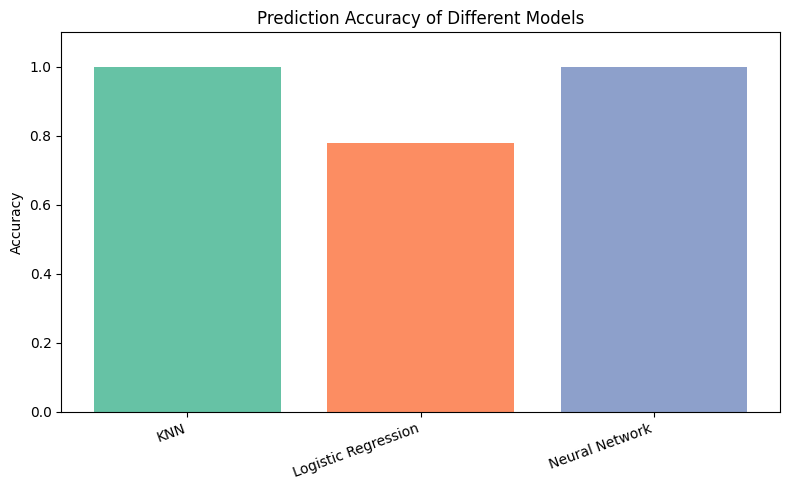

In [15]:
# accuracy of all models
accuracies = {name: accuracy_score(y_test, y_preds[name]) for name in fitted_models}
for name, acc in accuracies.items():
    print(f"{name} Accuracy: {acc:.4f}")

plt.figure(figsize=(8, 5))
bars = plt.bar(accuracies.keys(), accuracies.values(), color=sns.color_palette("Set2", len(accuracies)))
plt.ylabel("Accuracy")
plt.title("Prediction Accuracy of Different Models")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

In [24]:
# precision and recall
for name in fitted_models:
    prec = precision_score(y_test, y_preds[name])
    rec = recall_score(y_test, y_preds[name])
    print(f"{name:22s} Precision={prec:.4f}  Recall={rec:.4f}")

KNN                    Precision=1.0000  Recall=1.0000
Logistic Regression    Precision=0.8038  Recall=0.7979
Neural Network         Precision=0.9997  Recall=1.0000


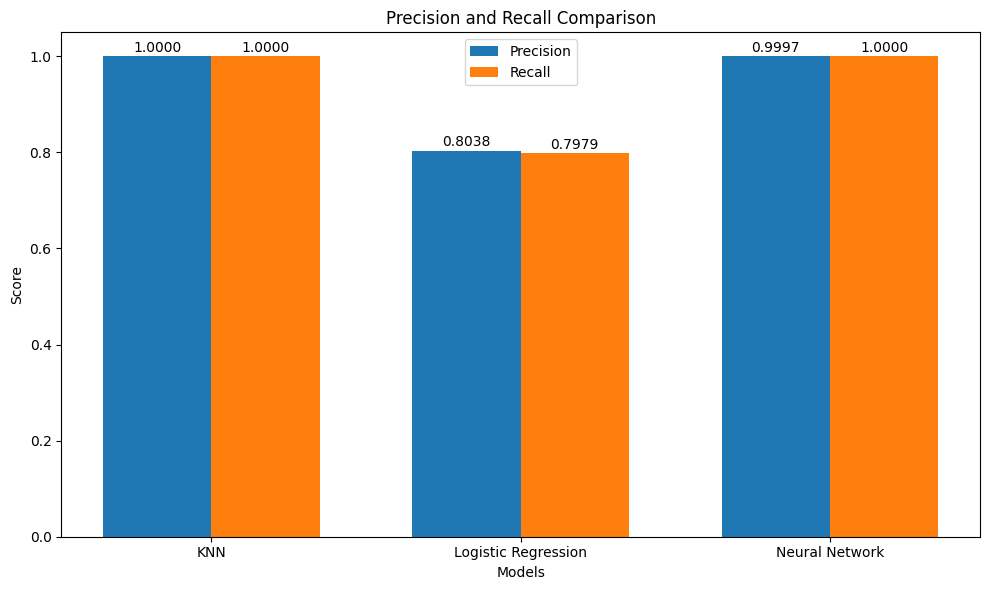

In [25]:
# Precision and recall plotting
import matplotlib.pyplot as plt
import numpy as np
models = ['KNN', 'Logistic Regression', 'Neural Network']
precision = [1.0000, 0.8038, 0.9997]
recall = [1.0000, 0.7979, 1.0000]
x = np.arange(len(models))
width = 0.35


plt.figure(figsize=(10, 6))
plt.bar(x - width/2, precision, width, label='Precision')
plt.bar(x + width/2, recall, width, label='Recall')
plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Precision and Recall Comparison')
plt.xticks(x, models)
plt.ylim(0, 1.05)
plt.legend()
for i, value in enumerate(precision):
    plt.text(i - width/2, value + 0.01, f'{value:.4f}',
             ha='center')

for i, value in enumerate(recall):
    plt.text(i + width/2, value + 0.01, f'{value:.4f}',
             ha='center')

plt.tight_layout()
plt.show()

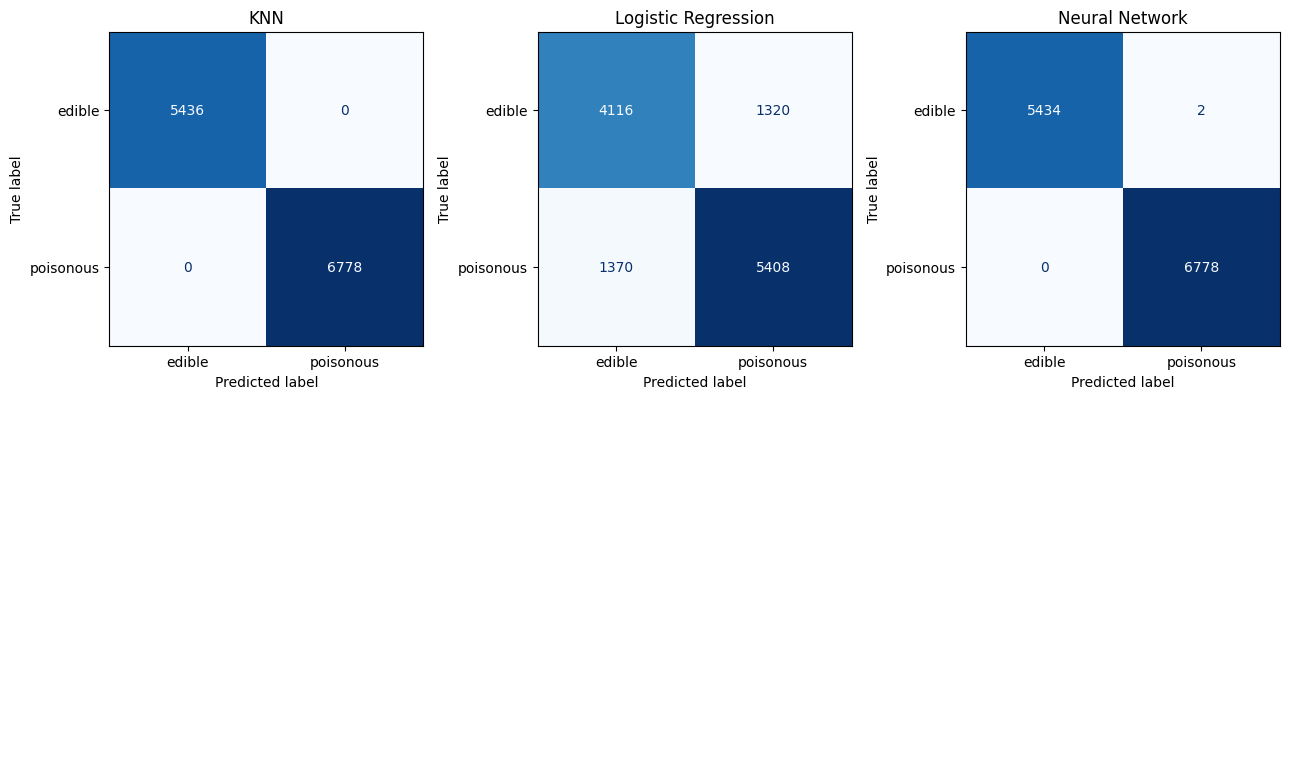

In [17]:
# confusion matrix for every model
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, name in zip(axes.flatten(), fitted_models):
    cm = confusion_matrix(y_test, y_preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["edible", "poisonous"]).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.flatten()[len(fitted_models):]:
    ax.axis("off")
plt.subplots_adjust(wspace=0.4)
plt.tight_layout()
plt.show()

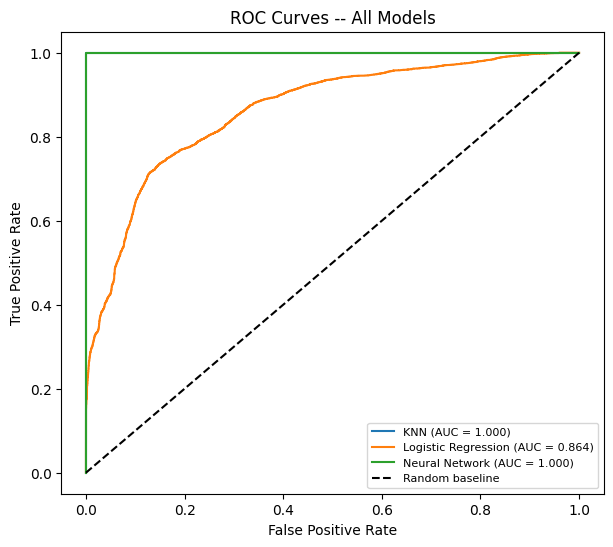

In [18]:
# AUC score, ROC curve for each model
plt.figure(figsize=(7, 6))
for name in fitted_models:
    fpr, tpr, _ = roc_curve(y_test, y_probas[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves -- All Models")
plt.legend(fontsize=8)
plt.show()

In [27]:
# classification report for the best-performing model
print(classification_report(y_test, y_preds["Neural Network"], target_names=["edible", "poisonous"]))

              precision    recall  f1-score   support

      edible       1.00      1.00      1.00      5436
   poisonous       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



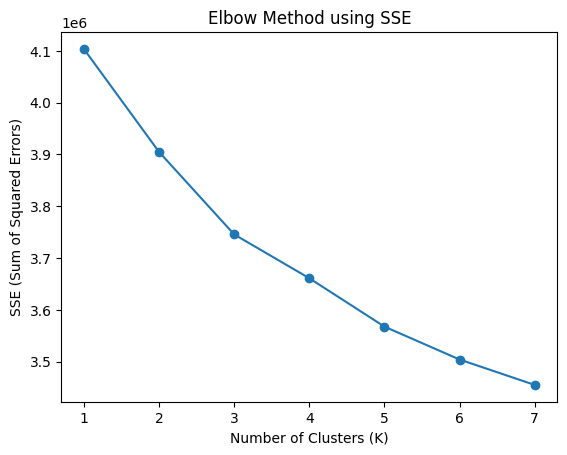

In [20]:
# get the value of K using elbow method
X_kmeans = X_train_scaled

sse = []
K_range = range(1, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_kmeans)
    sse.append(km.inertia_)

plt.plot(K_range, sse, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE (Sum of Squared Errors)")
plt.title("Elbow Method using SSE")
plt.show()

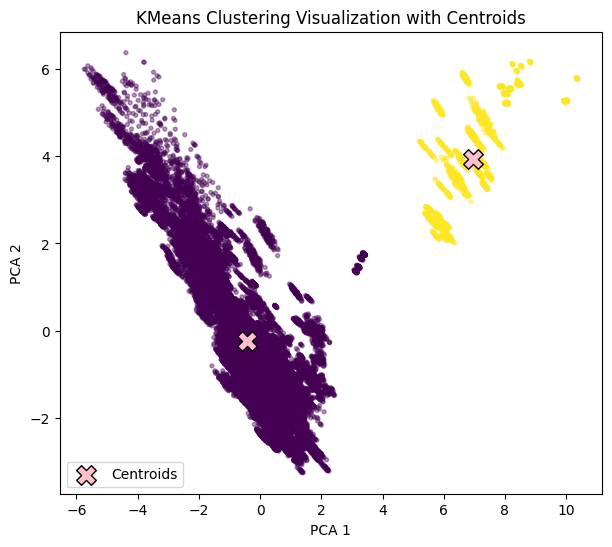

In [21]:
#compare directly against the 2 true classes
cluster = 2
km = KMeans(n_clusters=cluster, random_state=42, n_init=10)
clusters = km.fit_predict(X_kmeans)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_kmeans)
centroids_pca = pca.transform(km.cluster_centers_)

plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", s=8, alpha=0.4)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c="pink", marker="X", s=200,
            edgecolor="black", label="Centroids")
plt.title("KMeans Clustering Visualization with Centroids")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.show()

In [22]:
# compare clusters to true labels -- accuracy of the best alignment
acc_as_is = accuracy_score(y_train, clusters)
acc_flipped = accuracy_score(y_train, 1 - clusters)
clustering_acc = max(acc_as_is, acc_flipped)
print(f"K-Means clustering accuracy vs true edibility labels: {clustering_acc:.4f}")
print("barely above chance: the clusters do NOT line up with edibility.")

K-Means clustering accuracy vs true edibility labels: 0.5431
barely above chance: the clusters do NOT line up with edibility.


         cap-diameter  stem-height  stem-width
Cluster                                       
0            6.881475     6.744086   11.894563
1            4.495666     3.954310   16.407874


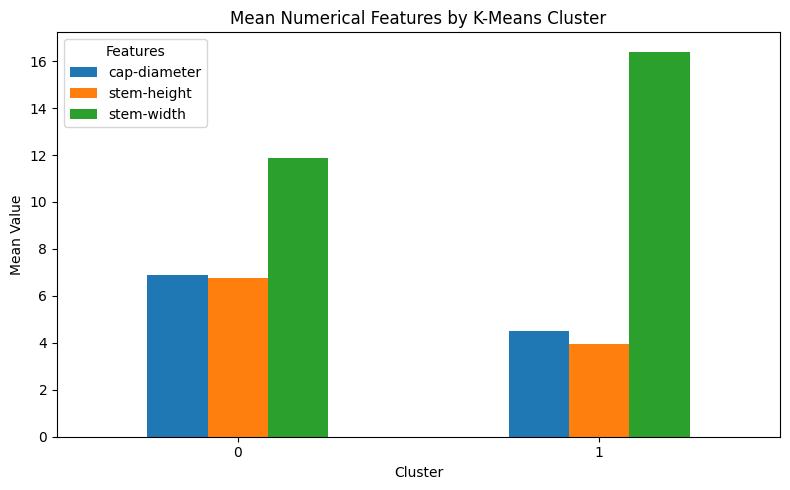

In [48]:
#numeric feature means
features = ["cap-diameter", "stem-height", "stem-width"]
kmeans_df = X_train[features].copy()
kmeans_df["Cluster"] = clusters
cluster_feature_means = kmeans_df.groupby("Cluster")[features].mean()

print(cluster_feature_means)

cluster_feature_means.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Mean Numerical Features by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean Value")
plt.xticks(rotation=0)
plt.legend(title="Features")
plt.tight_layout()
plt.show()

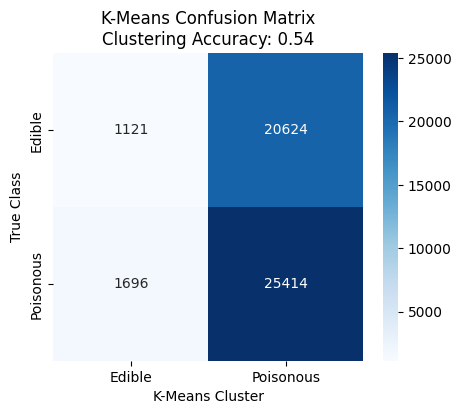

In [38]:
#confusion matrix for k-means
y_true = y_train
cluster_labels = clusters
cm1 = confusion_matrix(y_true, cluster_labels)
cm2 = confusion_matrix(y_true, 1 - cluster_labels)
acc1 = accuracy_score(y_true, cluster_labels)
acc2 = accuracy_score(y_true, 1 - cluster_labels)

if acc2 > acc1:
    cluster_labels = 1 - cluster_labels
    cm = cm2
    acc = acc2
else:
    cm = cm1
    acc = acc1
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Edible', 'Poisonous'],
    yticklabels=['Edible', 'Poisonous']
)

plt.xlabel('K-Means Cluster')
plt.ylabel('True Class')
plt.title(f'K-Means Confusion Matrix\nClustering Accuracy: {acc:.2f}')
plt.show()